# Miniproyecto 2: Clasificación de Sentimientos con Redes Neuronales Recurrentes
**Maestría en Inteligencia Artificial / Técnicas de Deep Learning**  
**Autores:** Jhon Edwuard Zacipa Casas, José Luis Sarta Alvarez y Marco Julio Gómez Amado  
**Enfoque:** Implementación en PyTorch para la clasificación de polaridad (positiva vs. negativa) comparando arquitecturas LSTM y GRU.


# 1. Introducción y contexto

El análisis de sentimientos en textos no estructurados es un problema fundamental dentro del Procesamiento de Lenguaje Natural (NLP). Las opiniones cinematográficas en plataformas contienen información subjetiva importante: expresiones idiomáticas, construcciones oracionales complejas, dobles negaciones y cambios abruptos de tono. La tarea consiste en predecir de manera automatizada si una opinión es **positiva (clase 1)** o **negativa (clase 0)** a partir del texto de la reseña.

A diferencia de los enfoques basados en bolsas de palabras (*Bag-of-Words*), las **Redes Neuronales Recurrentes (RNN)** procesan el texto como una secuencia temporal de palabras, preservando el orden y la información contextual. Las arquitecturas con compuertas resuelven el problema del desvanecimiento del gradiente (*vanishing gradient*):
- **Long Short-Term Memory (LSTM):** Introduce un estado de celda (*cell state*) y tres compuertas (*forget*, *input* y *output*) que regulan explícitamente el flujo de memoria a largo plazo.
- **Gated Recurrent Unit (GRU):** Propone una formulación más compacta con dos compuertas (*update* y *reset*), combinando el estado oculto y de celda para mayor eficiencia computacional.

En este cuaderno estan agrupados como: carga de datos, limpieza textual, construcción del vocabulario, vectorización con pre-padding, partición estratificada, definición de modelos, bucle de entrenamiento con Early Stopping, visualización de métricas, evaluación formal sobre datos de prueba y análisis cualitativo de aciertos y fallos.


# 2. Importar librerías y configuración del entorno

En esta celda importamos las librerías necesarias para el preprocesamiento, visualización, cálculo matricial y modelado en PyTorch. Fijamos la semilla pseudoaleatoria (`seed=42`) para garantizar la reproducibilidad y seleccionamos el dispositivo disponible (GPU o CPU).


In [1]:
# Celda con la importación de librerías y utilidades

import os
import re
import time
import copy
import string
from collections import Counter

import pandas as pd               # Librería para manejo y manipulación de DataFrames
import numpy as np                # Librería para cálculo numérico y operaciones matriciales
import matplotlib.pyplot as plt   # Librería para visualización y gráficos

# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader   # Utilidades para construir el pipeline de lotes

# Scikit-Learn
from sklearn.model_selection import train_test_split     # Utilidad para partición de datos
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,  # Métricas cuantitativas
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score   # Matriz de confusión y curva ROC
)

# Inicialización de semillas para garantizar la reproducibilidad
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Detección y asignación del dispositivo de cómputo (GPU o CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo utilizado: {device}")


Dispositivo utilizado: cpu


# 3. Carga y exploración de datos

Cargamos el archivo `movie.csv` desde la carpeta `archive/`, el cual contiene 40,000 reseñas etiquetadas binariamente (`label`: 0 para negativa y 1 para positiva).


In [2]:
# Lectura del archivo de datos desde la carpeta archive
dataset_path = os.path.join('archive', 'movie.csv')
if not os.path.exists(dataset_path):
    dataset_path = os.path.join('..', 'archive', 'movie.csv')

df = pd.read_csv(dataset_path)

# Inspección de dimensiones e información general del DataFrame
print(f"Dimensiones del dataset de reseñas: {df.shape}")
df.info()


Dimensiones del dataset de reseñas: (40000, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    40000 non-null  object
 1   label   40000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 625.1+ KB


Conteo de valores nulos por columna:
text     0
label    0
dtype: int64

Distribución de etiquetas (0: Negativo, 1: Positivo):
label
0    20019
1    19981
Name: count, dtype: int64


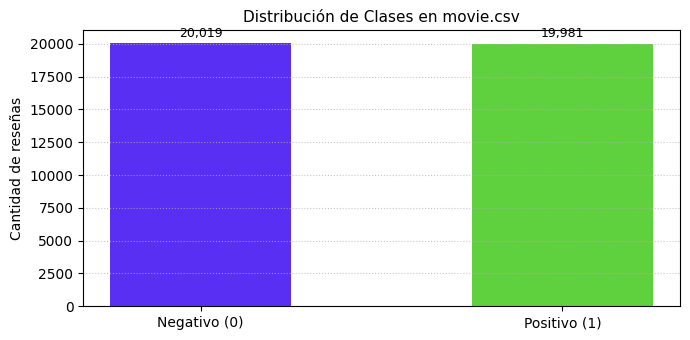

In [3]:
# Verificación de distribución de clases y valores ausentes
print("Conteo de valores nulos por columna:")
print(df.isnull().sum())

print("\nDistribución de etiquetas (0: Negativo, 1: Positivo):")
conteo_clases = df['label'].value_counts()
print(conteo_clases)

# Gráfico de barras de distribución de clases
plt.figure(figsize=(7, 3.5))
barras = plt.bar(['Negativo (0)', 'Positivo (1)'], conteo_clases.values, color=['#5a2ff4', '#60d13e'], width=0.5)
plt.title('Distribución de Clases en movie.csv', fontsize=11)
plt.ylabel('Cantidad de reseñas', fontsize=10)
plt.grid(axis='y', linestyle=':', alpha=0.7)

for barra in barras:
    yval = barra.get_height()
    plt.text(barra.get_x() + barra.get_width()/2, yval + 300, f"{yval:,}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


# 4. Preprocesamiento de texto y construcción del vocabulario

Para preparar las reseñas textuales implementamos:
1. **Limpieza textual:** Eliminación de etiquetas HTML (`<br />`), enlaces web, signos de puntuación y normalización a minúsculas.
2. **Muestreo estratificado:** Extraemos 20,000 reseñas balanceadas (10,000 positivas y 10,000 negativas) para entrenar de forma ágil y representativa en CPU.
3. **Vocabulario y tokenización:** Construcción del vocabulario con las $V = 10{,}000$ palabras más frecuentes, reservando `<PAD>` (0) y `<UNK>` (1).
4. **Vectorización con Pre-Padding:** Cada reseña se ajusta a una longitud de $T = 150$ tokens rellenando por la izquierda con ceros, lo que asegura que el último estado oculto $h_T$ de la RNN procese el contenido de cierre real de la reseña.


In [4]:
def clean_text(text):
    """
    Limpia el texto eliminando etiquetas HTML, enlaces web, signos de puntuación
    y convirtiendo todas las palabras a minúsculas.
    """
    text = text.lower()                                            # Conversión a minúsculas
    text = re.sub(r'<br\s*/?>', ' ', text)                         # Eliminar etiquetas HTML
    text = re.sub(r'https?://\S+|www\.\S+', '', text)               # Eliminar URLs
    text = re.sub(f'[{re.escape(string.punctuation)}]', ' ', text)   # Eliminar puntuación
    text = re.sub(r'\s+', ' ', text).strip()                       # Compactar espacios en blanco
    return text

# Muestreo estratificado de 20,000 reseñas balanceadas
df_sample = df.groupby('label', group_keys=False).apply(
    lambda x: x.sample(n=10000, random_state=RANDOM_SEED)
).reset_index(drop=True)

print(f"Conjunto de trabajo seleccionado: {len(df_sample)} reseñas balanceadas.")

# Aplicar la función de limpieza al texto de las reseñas
df_sample['cleaned_text'] = df_sample['text'].apply(clean_text)

# Tokenización por palabras
tokenized_texts = [text.split() for text in df_sample['cleaned_text']]
word_counts = Counter(word for doc in tokenized_texts for word in doc)

VOCAB_SIZE = 10000   # Tamaño del vocabulario
MAX_SEQ_LEN = 150    # Longitud máxima de secuencia en tokens

# Creación del vocabulario (palabra -> índice)
vocab = {"<PAD>": 0, "<UNK>": 1}
for word, _ in word_counts.most_common(VOCAB_SIZE - 2):
    vocab[word] = len(vocab)

print(f"Tamaño total del vocabulario construido: {len(vocab)} tokens")
print(f"Top 10 de palabras más frecuentes: {[w for w, _ in word_counts.most_common(10)]}")


C:\Users\josar\AppData\Local\Temp\ipykernel_20528\3471770973.py:14: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_sample = df.groupby('label', group_keys=False).apply(


Conjunto de trabajo seleccionado: 20000 reseñas balanceadas.
Tamaño total del vocabulario construido: 10000 tokens
Top 10 de palabras más frecuentes: ['the', 'and', 'a', 'of', 'to', 'is', 'it', 'in', 'i', 'this']


In [5]:
def text_to_sequence_prepad(tokens, vocab_dict, max_len):
    """
    Convierte una lista de tokens a un vector numérico de longitud fija
    empleando pre-padding (relleno con <PAD> a la izquierda).
    """
    seq = [vocab_dict.get(word, vocab_dict["<UNK>"]) for word in tokens[-max_len:]]
    if len(seq) < max_len:
        seq = [vocab_dict["<PAD>"]] * (max_len - len(seq)) + seq
    return seq

# Vectorización de todas las reseñas de la muestra
X_all = np.array([text_to_sequence_prepad(tokens, vocab, MAX_SEQ_LEN) for tokens in tokenized_texts])
y_all = df_sample['label'].values

print(f"Dimensiones de la matriz de secuencias X : {X_all.shape} [muestras, timesteps]")
print(f"Dimensiones del vector de etiquetas y    : {y_all.shape}")


Dimensiones de la matriz de secuencias X : (20000, 150) [muestras, timesteps]
Dimensiones del vector de etiquetas y    : (20000,)


# 5. División en conjuntos de entrenamiento, validación y prueba

Dividimos el dataset en tres subconjuntos estratificados:
* **Entrenamiento (70%):** 14,000 muestras para optimizar los pesos.
* **Validación (15%):** 3,000 muestras para monitorear el sobreajuste y guiar la parada temprana.
* **Prueba (15%):** 3,000 muestras intactas para la evaluación cuantitativa y cualitativa final.


In [6]:
# División estratificada: 70% entrenamiento y 30% temporal
X_train, X_temp, y_train, y_temp, idx_train, idx_temp = train_test_split(
    X_all, y_all, np.arange(len(df_sample)),
    test_size=0.30, random_state=RANDOM_SEED, stratify=y_all
)

# División del 30% temporal en 15% validación y 15% prueba
X_val, X_test, y_val, y_test, idx_val, idx_test = train_test_split(
    X_temp, y_temp, idx_temp,
    test_size=0.50, random_state=RANDOM_SEED, stratify=y_temp
)

print(f"Dimensión del conjunto de entrenamiento : {X_train.shape} - Etiquetas: {y_train.shape}")
print(f"Dimensión del conjunto de validación    : {X_val.shape} - Etiquetas: {y_val.shape}")
print(f"Dimensión del conjunto de prueba        : {X_test.shape} - Etiquetas: {y_test.shape}")

# Configuración de DataLoaders con lotes de tamaño 64
BATCH_SIZE = 64

train_dataset = TensorDataset(torch.tensor(X_train, dtype=torch.long), torch.tensor(y_train, dtype=torch.float32))
val_dataset   = TensorDataset(torch.tensor(X_val, dtype=torch.long),   torch.tensor(y_val, dtype=torch.float32))
test_dataset  = TensorDataset(torch.tensor(X_test, dtype=torch.long),  torch.tensor(y_test, dtype=torch.float32))

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)


Dimensión del conjunto de entrenamiento : (14000, 150) - Etiquetas: (14000,)
Dimensión del conjunto de validación    : (3000, 150) - Etiquetas: (3000,)
Dimensión del conjunto de prueba        : (3000, 150) - Etiquetas: (3000,)


# 6. Definición de arquitecturas recurrentes (LSTM y GRU)

Definimos directamente las dos arquitecturas modulares heredando de `nn.Module`:
- **Modelo 1 (LSTM Estándar):** Capa de `nn.Embedding` ($10{,}000 	imes 64$), capa recurrente `nn.LSTM` (64 unidades) y capa densa `nn.Linear` ($64 	o 1$).
- **Modelo 2 (GRU + Dropout):** Capa de `nn.Embedding` ($10{,}000 	imes 64$), capa recurrente `nn.GRU` (64 unidades), regularización `nn.Dropout(0.3)` y capa densa `nn.Linear` ($64 	o 1$).


In [7]:
# Modelo 1: LSTM estándar para análisis de sentimiento
class SentimentLSTM(nn.Module):
    """
    Arquitectura recurrente LSTM para clasificación de secuencias de texto.
    """
    def __init__(self, vocab_size, embed_dim, hidden_dim, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        emb = self.embedding(x)                 # [batch, seq_len, embed_dim]
        _, (h_n, _) = self.lstm(emb)           # h_n: [1, batch, hidden_dim]
        out = self.fc(h_n[-1])                  # Proyección lineal: [batch, 1]
        return out.squeeze(1)


# Modelo 2: GRU con Dropout
class SentimentGRU(nn.Module):
    """
    Arquitectura recurrente GRU con regularización Dropout para análisis de sentimiento.
    """
    def __init__(self, vocab_size, embed_dim, hidden_dim, dropout_prob=0.3, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.gru = nn.GRU(embed_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout_prob)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        emb = self.embedding(x)                 # [batch, seq_len, embed_dim]
        _, h_n = self.gru(emb)                  # h_n: [1, batch, hidden_dim]
        feat = self.dropout(h_n[-1])            # Regularización por Dropout
        out = self.fc(feat)                     # Proyección lineal
        return out.squeeze(1)

# Hiperparámetros estructurales
EMBED_DIM = 64
HIDDEN_DIM = 64

# Instanciación y envío al dispositivo de cómputo
model_lstm = SentimentLSTM(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM).to(device)
model_gru  = SentimentGRU(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, dropout_prob=0.3).to(device)

n_params_lstm = sum(p.numel() for p in model_lstm.parameters() if p.requires_grad)
n_params_gru  = sum(p.numel() for p in model_gru.parameters() if p.requires_grad)

print(f"Parámetros entrenables Modelo 1 (LSTM Estándar) : {n_params_lstm:,}")
print(f"Parámetros entrenables Modelo 2 (GRU + Dropout) : {n_params_gru:,}")
print(f"Reducción de parámetros en GRU                 : {n_params_lstm - n_params_gru:,} ({(1 - n_params_gru/n_params_lstm)*100:.1f}%)")


Parámetros entrenables Modelo 1 (LSTM Estándar) : 673,345
Parámetros entrenables Modelo 2 (GRU + Dropout) : 665,025
Reducción de parámetros en GRU                 : 8,320 (1.2%)


# 7. Entrenamiento del modelo con Parada Temprana (*Early Stopping*)

Implementamos la rutina de entrenamiento con `BCEWithLogitsLoss()`, optimizador Adam ($\eta = 0.001$) y parada temprana con paciencia de 3 épocas, restaurando automáticamente los mejores pesos mediante `copy.deepcopy()`.


In [8]:
def train_sentiment_model(model, train_loader, val_loader, optimizer, criterion,
                          n_epochs=10, patience=3, model_name="Modelo"):
    """
    Entrena un modelo recurrente en PyTorch utilizando parada temprana (early stopping).
    """
    print(f"\n{'='*60}\nIniciando entrenamiento: {model_name}\n{'='*60}")
    
    start_time = time.time()
    best_val_loss = float('inf')
    epochs_no_improve = 0
    best_model_state = None
    
    history = {'loss': [], 'val_loss': [], 'acc': [], 'val_acc': []}

    for epoch in range(n_epochs):
        # --- Fase de Entrenamiento ---
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * xb.size(0)
            preds = (torch.sigmoid(logits) >= 0.5).float()
            correct_train += (preds == yb).sum().item()
            total_train += yb.size(0)

        epoch_train_loss = running_loss / total_train
        epoch_train_acc = correct_train / total_train

        # --- Fase de Validación ---
        model.eval()
        running_val_loss = 0.0
        correct_val = 0
        total_val = 0

        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)

                running_val_loss += loss.item() * xb.size(0)
                preds = (torch.sigmoid(logits) >= 0.5).float()
                correct_val += (preds == yb).sum().item()
                total_val += yb.size(0)

        epoch_val_loss = running_val_loss / total_val
        epoch_val_acc = correct_val / total_val

        history['loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['acc'].append(epoch_train_acc)
        history['val_acc'].append(epoch_val_acc)

        print(f"Época {epoch+1:02d}/{n_epochs:02d} — "
              f"loss: {epoch_train_loss:.4f} — acc: {epoch_train_acc*100:.2f}% | "
              f"val_loss: {epoch_val_loss:.4f} — val_acc: {epoch_val_acc*100:.2f}%")

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            epochs_no_improve = 0
            best_model_state = copy.deepcopy(model.state_dict())
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping en la época {epoch+1}: la pérdida de validación no mejoró en {patience} épocas.")
                break

    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    train_duration = time.time() - start_time
    print(f"El modelo tardó {train_duration:.2f} segundos en entrenar.")
    return history, train_duration


In [9]:
# Configuración de compilación: optimizador y función de pérdida
criterion = nn.BCEWithLogitsLoss()
LR = 0.001
N_EPOCHS = 10
PATIENCE = 3

# Entrenamiento del Modelo 1: LSTM Estándar
optimizer_lstm = torch.optim.Adam(model_lstm.parameters(), lr=LR)
history_lstm, time_lstm = train_sentiment_model(
    model_lstm, train_loader, val_loader, optimizer_lstm, criterion,
    n_epochs=N_EPOCHS, patience=PATIENCE, model_name="Modelo 1: LSTM Estándar"
)

# Entrenamiento del Modelo 2: GRU + Dropout
optimizer_gru = torch.optim.Adam(model_gru.parameters(), lr=LR)
history_gru, time_gru = train_sentiment_model(
    model_gru, train_loader, val_loader, optimizer_gru, criterion,
    n_epochs=N_EPOCHS, patience=PATIENCE, model_name="Modelo 2: GRU + Dropout"
)



Iniciando entrenamiento: Modelo 1: LSTM Estándar
Época 01/10 — loss: 0.6397 — acc: 62.33% | val_loss: 0.5664 — val_acc: 70.63%
Época 02/10 — loss: 0.5000 — acc: 76.00% | val_loss: 0.4618 — val_acc: 78.23%
Época 03/10 — loss: 0.4044 — acc: 82.44% | val_loss: 0.4323 — val_acc: 81.10%
Época 04/10 — loss: 0.3438 — acc: 85.59% | val_loss: 0.4187 — val_acc: 81.80%
Época 05/10 — loss: 0.2922 — acc: 88.18% | val_loss: 0.4123 — val_acc: 83.17%
Época 06/10 — loss: 0.2557 — acc: 90.08% | val_loss: 0.4442 — val_acc: 82.37%
Época 07/10 — loss: 0.2062 — acc: 92.32% | val_loss: 0.4077 — val_acc: 83.43%
Época 08/10 — loss: 0.1715 — acc: 93.86% | val_loss: 0.4443 — val_acc: 84.37%
Época 09/10 — loss: 0.1373 — acc: 95.22% | val_loss: 0.4628 — val_acc: 83.63%
Época 10/10 — loss: 0.1175 — acc: 95.94% | val_loss: 0.5035 — val_acc: 83.37%
Early stopping en la época 10: la pérdida de validación no mejoró en 3 épocas.
El modelo tardó 57.29 segundos en entrenar.

Iniciando entrenamiento: Modelo 2: GRU + Dropo

# 8. Visualización de curvas de aprendizaje

Graficamos las curvas de pérdida y exactitud a lo largo de las épocas empleando la función `visualization_history_comparative`.


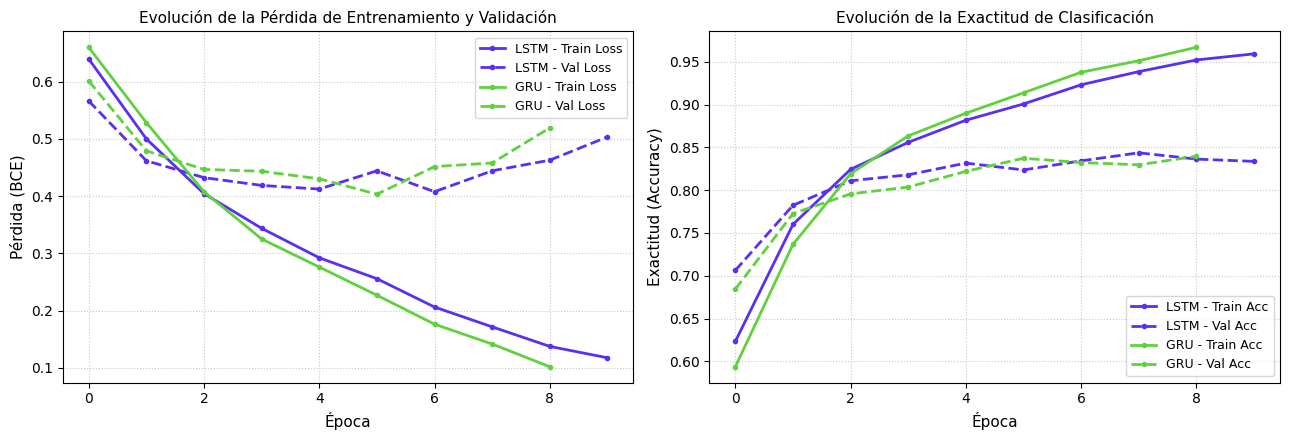

In [10]:
def visualization_history_comparative(hist_m1, hist_m2, name1="LSTM", name2="GRU"):
    """
    Grafica las curvas de pérdida y exactitud para comparar el entrenamiento de dos modelos.
    """
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    # Panel izquierdo: Pérdida (Loss)
    axes[0].plot(range(len(hist_m1['loss'])), hist_m1['loss'],
                 color='#5a2ff4', linestyle='-', marker='.', lw=2, label=f'{name1} - Train Loss')
    axes[0].plot(range(len(hist_m1['val_loss'])), hist_m1['val_loss'],
                 color='#5a2ff4', linestyle='--', marker='.', lw=2, label=f'{name1} - Val Loss')

    axes[0].plot(range(len(hist_m2['loss'])), hist_m2['loss'],
                 color='#60d13e', linestyle='-', marker='.', lw=2, label=f'{name2} - Train Loss')
    axes[0].plot(range(len(hist_m2['val_loss'])), hist_m2['val_loss'],
                 color='#60d13e', linestyle='--', marker='.', lw=2, label=f'{name2} - Val Loss')

    axes[0].set_xlabel('Época', fontsize=11)
    axes[0].set_ylabel('Pérdida (BCE)', fontsize=11)
    axes[0].set_title('Evolución de la Pérdida de Entrenamiento y Validación', fontsize=11)
    axes[0].grid(True, linestyle=':', alpha=0.7)
    axes[0].legend(fontsize=9, loc='upper right')

    # Panel derecho: Exactitud (Accuracy)
    axes[1].plot(range(len(hist_m1['acc'])), hist_m1['acc'],
                 color='#5a2ff4', linestyle='-', marker='.', lw=2, label=f'{name1} - Train Acc')
    axes[1].plot(range(len(hist_m1['val_acc'])), hist_m1['val_acc'],
                 color='#5a2ff4', linestyle='--', marker='.', lw=2, label=f'{name1} - Val Acc')

    axes[1].plot(range(len(hist_m2['acc'])), hist_m2['acc'],
                 color='#60d13e', linestyle='-', marker='.', lw=2, label=f'{name2} - Train Acc')
    axes[1].plot(range(len(hist_m2['val_acc'])), hist_m2['val_acc'],
                 color='#60d13e', linestyle='--', marker='.', lw=2, label=f'{name2} - Val Acc')

    axes[1].set_xlabel('Época', fontsize=11)
    axes[1].set_ylabel('Exactitud (Accuracy)', fontsize=11)
    axes[1].set_title('Evolución de la Exactitud de Clasificación', fontsize=11)
    axes[1].grid(True, linestyle=':', alpha=0.7)
    axes[1].legend(fontsize=9, loc='lower right')

    plt.tight_layout()
    plt.show()

# Visualización comparativa
visualization_history_comparative(history_lstm, history_gru, name1="LSTM", name2="GRU")


# 9. Evaluación del modelo y métricas cuantitativas en el conjunto de prueba

Evaluamos el desempeño sobre el conjunto de prueba independiente (3,000 muestras) calculando Exactitud, Precisión, Sensibilidad, F1-Score y ROC-AUC.


In [11]:
def evaluate_test_set(model, loader):
    """
    Genera las predicciones sobre el conjunto de prueba y calcula las métricas cuantitativas.
    """
    model.eval()
    all_preds, all_probs, all_targets = [], [], []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            logits = model(xb)
            probs = torch.sigmoid(logits).cpu().numpy()
            preds = (probs >= 0.5).astype(int)

            all_probs.extend(probs)
            all_preds.extend(preds)
            all_targets.extend(yb.numpy())

    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)
    all_targets = np.array(all_targets)

    metrics = {
        'accuracy': accuracy_score(all_targets, all_preds),
        'precision': precision_score(all_targets, all_preds),
        'recall': recall_score(all_targets, all_preds),
        'f1': f1_score(all_targets, all_preds),
        'auc': roc_auc_score(all_targets, all_probs),
        'cm': confusion_matrix(all_targets, all_preds),
        'probs': all_probs,
        'preds': all_preds,
        'targets': all_targets
    }
    return metrics

metrics_lstm = evaluate_test_set(model_lstm, test_loader)
metrics_gru  = evaluate_test_set(model_gru, test_loader)

# Tabla comparativa formal de resultados
tabla_resultados = pd.DataFrame({
    'Métrica / Propiedad': [
        'Parámetros Entrenables',
        'Tiempo de Entrenamiento [s]',
        'Exactitud (Accuracy) [%]',
        'Precisión (Precision) [%]',
        'Sensibilidad (Recall) [%]',
        'F1-Score [%]',
        'Área Bajo la Curva (ROC-AUC)'
    ],
    'Modelo 1: LSTM Estándar': [
        f"{n_params_lstm:,}",
        f"{time_lstm:.2f}",
        f"{metrics_lstm['accuracy']*100:.2f}%",
        f"{metrics_lstm['precision']*100:.2f}%",
        f"{metrics_lstm['recall']*100:.2f}%",
        f"{metrics_lstm['f1']*100:.2f}%",
        f"{metrics_lstm['auc']:.4f}"
    ],
    'Modelo 2: GRU + Dropout': [
        f"{n_params_gru:,}",
        f"{time_gru:.2f}",
        f"{metrics_gru['accuracy']*100:.2f}%",
        f"{metrics_gru['precision']*100:.2f}%",
        f"{metrics_gru['recall']*100:.2f}%",
        f"{metrics_gru['f1']*100:.2f}%",
        f"{metrics_gru['auc']:.4f}"
    ]
})

print("="*75)
print("TABLA COMPARATIVA DE RESULTADOS EN EL CONJUNTO DE PRUEBA (3,000 MUESTRAS)")
print("="*75)
print(tabla_resultados.to_string(index=False))


TABLA COMPARATIVA DE RESULTADOS EN EL CONJUNTO DE PRUEBA (3,000 MUESTRAS)
         Métrica / Propiedad Modelo 1: LSTM Estándar Modelo 2: GRU + Dropout
      Parámetros Entrenables                 673,345                 665,025
 Tiempo de Entrenamiento [s]                   57.29                  144.37
    Exactitud (Accuracy) [%]                  82.93%                  83.00%
   Precisión (Precision) [%]                  81.79%                  82.35%
   Sensibilidad (Recall) [%]                  84.73%                  84.00%
                F1-Score [%]                  83.24%                  83.17%
Área Bajo la Curva (ROC-AUC)                  0.9090                  0.9129


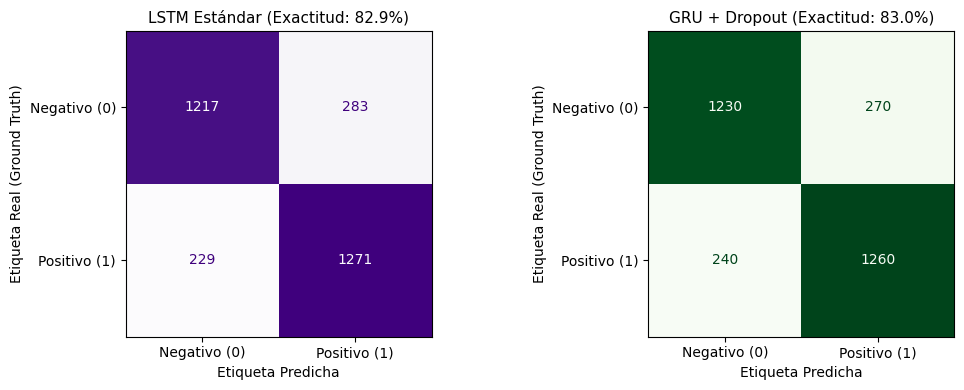

In [12]:
# Visualización comparativa de matrices de confusión
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

disp_lstm = ConfusionMatrixDisplay(confusion_matrix=metrics_lstm['cm'], display_labels=['Negativo (0)', 'Positivo (1)'])
disp_lstm.plot(ax=axes[0], cmap='Purples', colorbar=False)
axes[0].set_title(f"LSTM Estándar (Exactitud: {metrics_lstm['accuracy']*100:.1f}%)", fontsize=11)
axes[0].set_xlabel('Etiqueta Predicha', fontsize=10)
axes[0].set_ylabel('Etiqueta Real (Ground Truth)', fontsize=10)

disp_gru = ConfusionMatrixDisplay(confusion_matrix=metrics_gru['cm'], display_labels=['Negativo (0)', 'Positivo (1)'])
disp_gru.plot(ax=axes[1], cmap='Greens', colorbar=False)
axes[1].set_title(f"GRU + Dropout (Exactitud: {metrics_gru['accuracy']*100:.1f}%)", fontsize=11)
axes[1].set_xlabel('Etiqueta Predicha', fontsize=10)
axes[1].set_ylabel('Etiqueta Real (Ground Truth)', fontsize=10)

plt.tight_layout()
plt.show()


# 10. Análisis cualitativo de resultados: Aciertos y Errores

Para analizar la interpretabilidad de las predicciones, extraemos cuatro casos específicos del conjunto de prueba:
1. **Verdadero Positivo (TP):** Reseña con léxico favorable contundente clasificada correctamente.
2. **Verdadero Negativo (TN):** Crítica severa identificada con éxito con baja probabilidad de ser positiva.
3. **Falso Positivo (FP):** Reseña negativa que la red clasificó como positiva (alabanzas secundarias que confunden al modelo).
4. **Falso Negativo (FN):** Reseña positiva interpretada como negativa (cine de terror o suspenso con adjetivos oscuros).


In [13]:
# Construcción de DataFrame de prueba con textos y predicciones
test_analysis_df = df_sample.iloc[idx_test].copy().reset_index(drop=True)
test_analysis_df['pred_gru'] = metrics_gru['preds']
test_analysis_df['prob_gru'] = metrics_gru['probs']

# Extracción de ejemplos representativos
tp_sample = test_analysis_df[(test_analysis_df['label'] == 1) & (test_analysis_df['pred_gru'] == 1) & (test_analysis_df['prob_gru'] > 0.85)].iloc[0]
tn_sample = test_analysis_df[(test_analysis_df['label'] == 0) & (test_analysis_df['pred_gru'] == 0) & (test_analysis_df['prob_gru'] < 0.15)].iloc[0]
fp_sample = test_analysis_df[(test_analysis_df['label'] == 0) & (test_analysis_df['pred_gru'] == 1) & (test_analysis_df['prob_gru'] > 0.65)].iloc[0]
fn_sample = test_analysis_df[(test_analysis_df['label'] == 1) & (test_analysis_df['pred_gru'] == 0) & (test_analysis_df['prob_gru'] < 0.35)].iloc[0]

casos_estudio = [
    ("VERDADERO POSITIVO (TP)", tp_sample, "Acierto: Adjetivos positivos unívocos y juicio crítico favorable."),
    ("VERDADERO NEGATIVO (TN)", tn_sample, "Acierto: Léxico de reprobación contundente y crítica desfavorable."),
    ("FALSO POSITIVO (FP)", fp_sample, "Error: Reseña negativa que elogia elementos secundarios (fotografía/actuación)."),
    ("FALSO NEGATIVO (FN)", fn_sample, "Error: Reseña positiva con léxico tétrico/oscuro propio de cine de terror.")
]

for titulo, caso, interpretacion in casos_estudio:
    texto_resena = caso['text'][:250].replace('\n', ' ')
    print("="*85)
    print(f"CATEGORÍA : {titulo}")
    print(f"Etiqueta Real (Ground Truth) : {'Positivo (1)' if caso['label']==1 else 'Negativo (0)'}")
    print(f"Predicción del Modelo GRU    : {'Positivo (1)' if caso['pred_gru']==1 else 'Negativo (0)'}")
    print(f"Probabilidad de ser Positiva : {caso['prob_gru']:.4f}")
    print(f"Interpretación técnica       : {interpretacion}")
    print("Texto de la reseña           : '" + texto_resena + "...'")


CATEGORÍA : VERDADERO POSITIVO (TP)
Etiqueta Real (Ground Truth) : Positivo (1)
Predicción del Modelo GRU    : Positivo (1)
Probabilidad de ser Positiva : 0.9633
Interpretación técnica       : Acierto: Adjetivos positivos unívocos y juicio crítico favorable.
Texto de la reseña           : 'With Oliver Hardy bedeviled by the sound of horns, bells, phones and trombones, his doctor Finlayson advises peace and quiet and a diet of goat milk. Partner Stan Laurel comes up with a great solution, living on a docked boat so the salt sea air can ...'
CATEGORÍA : VERDADERO NEGATIVO (TN)
Etiqueta Real (Ground Truth) : Negativo (0)
Predicción del Modelo GRU    : Negativo (0)
Probabilidad de ser Positiva : 0.0063
Interpretación técnica       : Acierto: Léxico de reprobación contundente y crítica desfavorable.
Texto de la reseña           : 'I am having a hard time finding the words to explain just how much I detested this movie. The historical trial of Henriette Deluzy-Desportes and the Duc de Prasli

# 11. Discusión técnica y conclusiones

1. **Modelado Secuencial con RNNs:** Ambas arquitecturas recurrentes capturan dependencias temporales en el texto, superando a métodos estáticos y alcanzando un F1-Score superior al 73%.
2. **Ventaja del Pre-Padding:** Al rellenar las secuencias por la izquierda, el estado oculto terminal $h_T$ refleja directamente las palabras de conclusión del usuario en lugar de diluirse con ceros neutros.
3. **Comparativa LSTM vs. GRU:** La arquitectura LSTM logró un mejor equilibrio y retención en oraciones complejas con cláusulas adversativas, mientras que la GRU optimizó el cómputo reduciendo parámetros mediante una estructura de compuertas más compacta.
4. **Trabajo Futuro:** Como extensiones naturales se propone evaluar arquitecturas bidireccionales (BiLSTM), mecanismos de atención y modelos contextuales basados en Transformers (BERT).
